# StreamFlix Content Analytics
## Phase 3 — KPI Calculations

**Project:** StreamFlix Content Analytics  
**Phase:** 3 — KPI Calculations  
**Analyst:** Kashif Siddique  
**Tools:** Python, Pandas, NumPy, Matplotlib, Jupyter Notebook  

### Objective

To calculate the 10 business KPIs required by the StreamFlix project brief and convert the platform data into management-ready measures of engagement, subscriber health, revenue, conversion, and content performance.

This notebook also completes the optional **Cohort Retention** challenge.

> **Working principle:** All KPI values are calculated directly from the data. No KPI result is hardcoded.

## Table of Contents

1. Environment Setup  
2. Import Libraries  
3. Load Datasets  
4. KPI Preparation & Validation  
5. Total Watch Hours  
6. Active Rate  
7. Churn Rate  
8. Average Completion Rate  
9. Monthly Recurring Revenue (MRR)  
10. ARPU  
11. Average Watch Time / Subscriber  
12. Watchlist Conversion  
13. Hit Concentration  
14. Originals Share of Hours  
15. KPI Summary & Target Assessment  
16. Bonus — Cohort Retention  
17. KPI Validation Checks  
18. Export KPI Outputs  
19. Phase 3 Business Summary  
20. PRD Requirement Checklist  
21. Phase 3 Conclusion  
22. Phase 3 Completion Status

## 1. Environment Setup

In [1]:
# ------------------------------------------------------------
# ENVIRONMENT SETUP
# Prefer the cleaned files produced in Phase 1.
# A raw-data fallback keeps the notebook executable in environments
# where the cleaned exports are not available.
# ------------------------------------------------------------

from pathlib import Path

EXPECTED_TABLES = [
    "subscribers",
    "titles",
    "watch_history",
    "ratings",
    "reviews",
    "watchlist",
]

candidate_clean_dirs = [
    Path("../data/cleaned"),
    Path("data/cleaned"),
    Path("/mnt/data/streamflix_phase1_workspace/cleaned"),
]

candidate_raw_dirs = [
    Path("../data/raw"),
    Path("data/raw"),
    Path("/mnt/data"),
]

DATA_DIR = None
USING_CLEANED_DATA = False

for candidate in candidate_clean_dirs:
    if all((candidate / f"{table}_clean.csv").exists() for table in EXPECTED_TABLES):
        DATA_DIR = candidate
        USING_CLEANED_DATA = True
        break

if DATA_DIR is None:
    for candidate in candidate_raw_dirs:
        if all((candidate / f"{table}.csv").exists() for table in EXPECTED_TABLES):
            DATA_DIR = candidate
            break

if DATA_DIR is None:
    raise FileNotFoundError("Could not locate the StreamFlix CSV files.")

if DATA_DIR.name == "cleaned" and DATA_DIR.parent.name == "data":
    PROJECT_ROOT = DATA_DIR.parent.parent
    TABLE_DIR = PROJECT_ROOT / "outputs" / "tables" / "phase3"
    CHART_DIR = PROJECT_ROOT / "outputs" / "charts" / "phase3"
else:
    PROJECT_ROOT = Path("/mnt/data/streamflix_phase3_generated")
    TABLE_DIR = PROJECT_ROOT / "phase3_tables"
    CHART_DIR = PROJECT_ROOT / "phase3_charts"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Data directory :", DATA_DIR.resolve())
print("Data source    :", "Phase 1 cleaned data" if USING_CLEANED_DATA else "Raw fallback")
print("Table output   :", TABLE_DIR.resolve())
print("Chart output   :", CHART_DIR.resolve())

Data directory : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Data\Cleaned
Data source    : Phase 1 cleaned data
Table output   : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Outputs\Tables\phase3
Chart output   : C:\Users\DELL4\OneDrive\Documents\Internmo\StreamFlix Content Analytics Project\Outputs\Charts\phase3


## 2. Import Libraries

In [2]:
# ------------------------------------------------------------
# IMPORT LIBRARIES
# pandas     -> data manipulation and KPI calculations
# numpy      -> numerical helpers
# matplotlib -> cohort-retention visualization
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Data Dictionary reference date used for tenure/retention maturity.
REFERENCE_DATE = pd.Timestamp("2026-06-01")

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load Datasets

In [3]:
# ------------------------------------------------------------
# LOAD ALL SIX TABLES
# Phase 3 needs subscribers, titles, watch_history, and watchlist
# directly, but all six tables are loaded for a consistent project setup.
# ------------------------------------------------------------

dfs = {}

for table in EXPECTED_TABLES:
    filename = f"{table}_clean.csv" if USING_CLEANED_DATA else f"{table}.csv"
    dfs[table] = pd.read_csv(DATA_DIR / filename, low_memory=False)

# Parse the dates required for retention analysis.
dfs["subscribers"]["signup_date"] = pd.to_datetime(
    dfs["subscribers"]["signup_date"], errors="coerce"
)
dfs["subscribers"]["churn_date"] = pd.to_datetime(
    dfs["subscribers"]["churn_date"], errors="coerce"
)
dfs["watch_history"]["watch_date"] = pd.to_datetime(
    dfs["watch_history"]["watch_date"], errors="coerce"
)

total_records = sum(len(df) for df in dfs.values())

print(f"Datasets loaded : {len(dfs)}")
print(f"Total records   : {total_records:,}")

for table, df in dfs.items():
    print(f"{table:15s}: {len(df):,} rows × {len(df.columns)} columns")

Datasets loaded : 6
Total records   : 979,000
subscribers    : 15,000 rows × 14 columns
titles         : 9,000 rows × 21 columns
watch_history  : 650,000 rows × 10 columns
ratings        : 130,000 rows × 5 columns
reviews        : 110,000 rows × 7 columns
watchlist      : 65,000 rows × 5 columns


## 4. KPI Preparation & Validation

In [4]:
# ------------------------------------------------------------
# CREATE ANALYSIS TABLES
# Short variable names make the later formulas easier to read.
# watch_hours is created once so all KPI calculations use the same
# definition: watch_duration_min / 60.
# ------------------------------------------------------------

subscribers = dfs["subscribers"].copy()
titles = dfs["titles"].copy()
watch = dfs["watch_history"].copy()
watchlist = dfs["watchlist"].copy()

watch["watch_hours"] = watch["watch_duration_min"] / 60

# Join title metadata for the Originals KPI.
watch_titles = watch.merge(
    titles[["title_id", "title_name", "is_original"]],
    on="title_id",
    how="left",
    validate="many_to_one"
)

pre_kpi_validation = pd.DataFrame([
    {"check": "Missing subscriber IDs in subscribers", "value": int(subscribers["subscriber_id"].isna().sum())},
    {"check": "Missing title IDs in titles", "value": int(titles["title_id"].isna().sum())},
    {"check": "Missing subscriber IDs in watch_history", "value": int(watch["subscriber_id"].isna().sum())},
    {"check": "Missing title IDs in watch_history", "value": int(watch["title_id"].isna().sum())},
    {"check": "Unmatched title joins", "value": int(watch_titles["is_original"].isna().sum())},
])

display(pre_kpi_validation)
assert pre_kpi_validation["value"].sum() == 0

,check,value
0,Missing subscriber IDs in subscribers,0
1,Missing title IDs in titles,0
2,Missing subscriber IDs in watch_history,0
3,Missing title IDs in watch_history,0
4,Unmatched title joins,0


## 5. KPI 1 — Total Watch Hours

**Formula:** `SUM(watch_duration_min) ÷ 60`  
**Why it matters:** Total engagement / size of the platform.

In [5]:
# KPI 1 — TOTAL WATCH HOURS
total_watch_hours = watch["watch_duration_min"].sum() / 60

print(f"Total Watch Hours: {total_watch_hours:,.2f}")

Total Watch Hours: 3,333,467.73


In [6]:
display(Markdown(
    f"**Finding:** StreamFlix generated **{total_watch_hours:,.0f} total watch hours** "
    "across the available viewing history."
))

**Finding:** StreamFlix generated **3,333,468 total watch hours** across the available viewing history.

## 6. KPI 2 — Active Rate

**Formula:** `Active Subscribers ÷ Total Subscribers × 100`  
**Target:** `> 70%`

In [7]:
# KPI 2 — ACTIVE RATE
total_subscribers = len(subscribers)
active_subscribers = int(subscribers["is_active"].sum())

active_rate = active_subscribers / total_subscribers * 100
active_target_met = active_rate > 70

print(f"Total Subscribers : {total_subscribers:,}")
print(f"Active Subscribers: {active_subscribers:,}")
print(f"Active Rate       : {active_rate:.2f}%")
print(f"Target > 70%      : {'Met' if active_target_met else 'Not Met'}")

Total Subscribers : 15,000
Active Subscribers: 11,199
Active Rate       : 74.66%
Target > 70%      : Met


In [8]:
display(Markdown(
    f"**Finding:** The active rate is **{active_rate:.2f}%**, so the >70% target is "
    f"**{'met' if active_target_met else 'not met'}**."
))

**Finding:** The active rate is **74.66%**, so the >70% target is **met**.

## 7. KPI 3 — Churn Rate

**Formula:** `Inactive Subscribers ÷ Total Subscribers × 100`  
**Target:** `< 30%`

In [9]:
# KPI 3 — CHURN RATE
inactive_subscribers = total_subscribers - active_subscribers

churn_rate = inactive_subscribers / total_subscribers * 100
churn_target_met = churn_rate < 30

print(f"Inactive Subscribers: {inactive_subscribers:,}")
print(f"Churn Rate          : {churn_rate:.2f}%")
print(f"Target < 30%        : {'Met' if churn_target_met else 'Not Met'}")

Inactive Subscribers: 3,801
Churn Rate          : 25.34%
Target < 30%        : Met


In [10]:
display(Markdown(
    f"**Finding:** The churn rate is **{churn_rate:.2f}%**, so the <30% target is "
    f"**{'met' if churn_target_met else 'not met'}**."
))

**Finding:** The churn rate is **25.34%**, so the <30% target is **met**.

## 8. KPI 4 — Average Completion Rate

**Formula:** `AVG(completion_pct)`  
**Target:** `> 60%`

In [11]:
# KPI 4 — AVERAGE COMPLETION RATE
avg_completion_rate = watch["completion_pct"].mean()
completion_target_met = avg_completion_rate > 60

print(f"Average Completion Rate: {avg_completion_rate:.2f}%")
print(f"Target > 60%            : {'Met' if completion_target_met else 'Not Met'}")

Average Completion Rate: 65.31%
Target > 60%            : Met


In [12]:
display(Markdown(
    f"**Finding:** Average completion is **{avg_completion_rate:.2f}%**, which "
    f"**{'meets' if completion_target_met else 'does not meet'}** the project target."
))

**Finding:** Average completion is **65.31%**, which **meets** the project target.

## 9. KPI 5 — Monthly Recurring Revenue (MRR)

**Formula:** `SUM(monthly_price_usd)` for active subscribers

In [13]:
# KPI 5 — MONTHLY RECURRING REVENUE
active_rows = subscribers[subscribers["is_active"]].copy()
mrr = active_rows["monthly_price_usd"].sum()

print(f"Monthly Recurring Revenue: ${mrr:,.2f}")

Monthly Recurring Revenue: $175,868.51


In [14]:
display(Markdown(
    f"**Finding:** Current active subscriptions generate approximately "
    f"**${mrr:,.2f} in MRR**."
))

**Finding:** Current active subscriptions generate approximately **$175,868.51 in MRR**.

## 10. KPI 6 — ARPU

**Formula:** `MRR ÷ Active Subscribers`

In [15]:
# KPI 6 — AVERAGE REVENUE PER USER
arpu = mrr / active_subscribers

print(f"ARPU: ${arpu:,.2f} per active subscriber")

ARPU: $15.70 per active subscriber


In [16]:
display(Markdown(
    f"**Finding:** Average recurring revenue is **${arpu:,.2f} per active subscriber per month**."
))

**Finding:** Average recurring revenue is **$15.70 per active subscriber per month**.

## 11. KPI 7 — Average Watch Time / Subscriber

**Formula from PRD:** `Total Watch Hours ÷ Active Subscribers`

In [17]:
# KPI 7 — AVERAGE WATCH TIME / SUBSCRIBER
# The PRD explicitly uses active subscribers as the denominator.
avg_watch_time_per_subscriber = total_watch_hours / active_subscribers

print(f"Average Watch Time / Active Subscriber: {avg_watch_time_per_subscriber:,.2f} hours")

Average Watch Time / Active Subscriber: 297.66 hours


In [18]:
display(Markdown(
    f"**Finding:** Applying the PRD formula gives **{avg_watch_time_per_subscriber:,.2f} "
    "historical watch hours per active subscriber**."
))

**Finding:** Applying the PRD formula gives **297.66 historical watch hours per active subscriber**.

## 12. KPI 8 — Watchlist Conversion

**Formula:** `Watched ÷ Watchlist Entries × 100`  
**Target:** `> 40%`

In [19]:
# KPI 8 — WATCHLIST CONVERSION
watchlist_entries = len(watchlist)
watchlist_converted = int(watchlist["watched"].sum())

watchlist_conversion_rate = watchlist_converted / watchlist_entries * 100
watchlist_target_met = watchlist_conversion_rate > 40

print(f"Watchlist Entries   : {watchlist_entries:,}")
print(f"Converted to Watched: {watchlist_converted:,}")
print(f"Conversion Rate     : {watchlist_conversion_rate:.2f}%")
print(f"Target > 40%        : {'Met' if watchlist_target_met else 'Not Met'}")

Watchlist Entries   : 65,000
Converted to Watched: 30,048
Conversion Rate     : 46.23%
Target > 40%        : Met


In [20]:
display(Markdown(
    f"**Finding:** Watchlist conversion is **{watchlist_conversion_rate:.2f}%**, so the "
    f">40% target is **{'met' if watchlist_target_met else 'not met'}**."
))

**Finding:** Watchlist conversion is **46.23%**, so the >40% target is **met**.

## 13. KPI 9 — Hit Concentration

**Formula:** `Plays from Top 10% Titles ÷ Total Plays × 100`

In [21]:
# ------------------------------------------------------------
# KPI 9 — HIT CONCENTRATION
# Count plays by title, rank titles, then measure the share of plays
# generated by the top 10% of titles.
# ------------------------------------------------------------

plays_by_title = (
    watch.groupby("title_id")
    .size()
    .sort_values(ascending=False)
    .rename("plays")
)

top_10pct_title_count = int(np.ceil(len(plays_by_title) * 0.10))
top_10pct_plays = plays_by_title.head(top_10pct_title_count).sum()
total_plays = plays_by_title.sum()

hit_concentration = top_10pct_plays / total_plays * 100

print(f"Titles with plays   : {len(plays_by_title):,}")
print(f"Top 10% title count : {top_10pct_title_count:,}")
print(f"Top 10% title plays : {top_10pct_plays:,}")
print(f"Total plays         : {total_plays:,}")
print(f"Hit Concentration   : {hit_concentration:.2f}%")

Titles with plays   : 9,000
Top 10% title count : 900
Top 10% title plays : 201,417
Total plays         : 650,000
Hit Concentration   : 30.99%


In [22]:
display(Markdown(
    f"**Finding:** The top **{top_10pct_title_count:,} titles** generate "
    f"**{hit_concentration:.2f}% of all plays**."
))

**Finding:** The top **900 titles** generate **30.99% of all plays**.

## 14. KPI 10 — Originals Share of Hours

**Formula:** `Hours on Originals ÷ Total Hours × 100`

In [23]:
# KPI 10 — ORIGINALS SHARE OF WATCH HOURS
original_watch_hours = watch_titles.loc[
    watch_titles["is_original"],
    "watch_hours"
].sum()

originals_share_of_hours = original_watch_hours / total_watch_hours * 100

print(f"Original Watch Hours     : {original_watch_hours:,.2f}")
print(f"Total Watch Hours        : {total_watch_hours:,.2f}")
print(f"Originals Share of Hours : {originals_share_of_hours:.2f}%")

Original Watch Hours     : 905,661.77
Total Watch Hours        : 3,333,467.73
Originals Share of Hours : 27.17%


In [24]:
display(Markdown(
    f"**Finding:** StreamFlix Originals contribute **{originals_share_of_hours:.2f}%** "
    f"of total watch hours, equal to roughly **{original_watch_hours:,.0f} hours**."
))

**Finding:** StreamFlix Originals contribute **27.17%** of total watch hours, equal to roughly **905,662 hours**.

## 15. KPI Summary & Target Assessment

In [25]:
# ------------------------------------------------------------
# KPI SUMMARY TABLE
# Include target/status only where the project brief explicitly
# provides a threshold.
# ------------------------------------------------------------

kpi_summary = pd.DataFrame([
    ["Total Watch Hours", f"{total_watch_hours:,.2f} hours", "—", "Informational"],
    ["Active Rate", f"{active_rate:.2f}%", "> 70%", "Met" if active_target_met else "Not Met"],
    ["Churn Rate", f"{churn_rate:.2f}%", "< 30%", "Met" if churn_target_met else "Not Met"],
    ["Avg Completion Rate", f"{avg_completion_rate:.2f}%", "> 60%", "Met" if completion_target_met else "Not Met"],
    ["Monthly Recurring Revenue", f"${mrr:,.2f}", "—", "Informational"],
    ["ARPU", f"${arpu:,.2f}", "—", "Informational"],
    ["Avg Watch Time / Subscriber", f"{avg_watch_time_per_subscriber:,.2f} hours", "—", "Informational"],
    ["Watchlist Conversion", f"{watchlist_conversion_rate:.2f}%", "> 40%", "Met" if watchlist_target_met else "Not Met"],
    ["Hit Concentration", f"{hit_concentration:.2f}%", "—", "Informational"],
    ["Originals Share of Hours", f"{originals_share_of_hours:.2f}%", "—", "Informational"],
], columns=["KPI", "Value", "Target", "Status"])

display(kpi_summary)

target_kpis = kpi_summary[kpi_summary["Target"] != "—"].reset_index(drop=True)
display(target_kpis)

print(
    f"Explicit KPI targets met: "
    f"{(target_kpis['Status'] == 'Met').sum()} / {len(target_kpis)}"
)

,KPI,Value,Target,Status
0,Total Watch Hours,"3,333,467.73 hours",—,Informational
1,Active Rate,74.66%,> 70%,Met
2,Churn Rate,25.34%,< 30%,Met
3,Avg Completion Rate,65.31%,> 60%,Met
4,Monthly Recurring Revenue,"$175,868.51",—,Informational
5,ARPU,$15.70,—,Informational
6,Avg Watch Time / Subscriber,297.66 hours,—,Informational
7,Watchlist Conversion,46.23%,> 40%,Met
8,Hit Concentration,30.99%,—,Informational
9,Originals Share of Hours,27.17%,—,Informational


,KPI,Value,Target,Status
0,Active Rate,74.66%,> 70%,Met
1,Churn Rate,25.34%,< 30%,Met
2,Avg Completion Rate,65.31%,> 60%,Met
3,Watchlist Conversion,46.23%,> 40%,Met


Explicit KPI targets met: 4 / 4


## 16. Bonus — Cohort Retention

Subscribers are grouped by **signup month**. For each 3-, 6-, and 12-month horizon, a subscriber is counted as retained when the subscriber had not churned by that horizon.

To avoid incomplete cohort measurements, a signup-month cohort is only shown for a horizon after **every subscriber in that cohort has had enough time to reach the horizon** by the reference date (`2026-06-01`).

In [26]:
# ------------------------------------------------------------
# BONUS — COHORT RETENTION
# Measure survival at 3, 6, and 12 months after signup.
# ------------------------------------------------------------

cohort_base = subscribers[
    ["subscriber_id", "signup_date", "churn_date"]
].copy()

cohort_base["signup_cohort"] = (
    cohort_base["signup_date"]
    .dt.to_period("M")
    .astype(str)
)

cohort_results = []

for horizon in [3, 6, 12]:
    temp = cohort_base.copy()

    # Date when each individual subscriber reaches the horizon.
    temp["horizon_date"] = (
        temp["signup_date"] + pd.DateOffset(months=horizon)
    )

    # A cohort is mature only when its latest subscriber has reached
    # the horizon by the project reference date.
    cohort_mature = (
        temp.groupby("signup_cohort")["horizon_date"]
        .max()
        .le(REFERENCE_DATE)
    )

    mature_cohorts = cohort_mature[cohort_mature].index
    temp = temp[temp["signup_cohort"].isin(mature_cohorts)].copy()

    # Retained if churn is blank or churn occurred after the horizon.
    temp["retained"] = (
        temp["churn_date"].isna()
        | (temp["churn_date"] > temp["horizon_date"])
    )

    summary = (
        temp.groupby("signup_cohort")
        .agg(
            cohort_size=("subscriber_id", "size"),
            retained_subscribers=("retained", "sum"),
        )
        .reset_index()
    )

    summary["horizon_months"] = horizon
    summary["retention_rate_pct"] = (
        summary["retained_subscribers"]
        / summary["cohort_size"]
        * 100
    )

    cohort_results.append(summary)

cohort_retention_long = pd.concat(cohort_results, ignore_index=True)

display(cohort_retention_long.head(10))

,signup_cohort,cohort_size,retained_subscribers,horizon_months,retention_rate_pct
0,2016-01,4,3,3,75.000000
1,2016-02,9,8,3,88.888889
2,2016-03,12,12,3,100.000000
3,2016-04,13,13,3,100.000000
4,2016-05,20,20,3,100.000000
5,2016-06,21,21,3,100.000000
6,2016-07,17,17,3,100.000000
7,2016-08,24,24,3,100.000000
8,2016-09,21,21,3,100.000000
9,2016-10,33,32,3,96.969697


In [27]:
# Pivot into a manager-friendly cohort table.
cohort_retention_table = (
    cohort_retention_long
    .pivot(
        index="signup_cohort",
        columns="horizon_months",
        values="retention_rate_pct",
    )
    .rename(columns={
        3: "Retention 3M (%)",
        6: "Retention 6M (%)",
        12: "Retention 12M (%)",
    })
)

display(cohort_retention_table.round(2).tail(24))

horizon_months,Retention 3M (%),Retention 6M (%),Retention 12M (%)
signup_cohort,,,
2024-03,98.18,96.97,93.94
2024-04,98.48,95.96,89.90
2024-05,98.90,94.51,91.21
2024-06,97.96,93.37,88.78
2024-07,98.86,96.00,87.43
2024-08,97.37,90.53,81.05
2024-09,97.75,94.94,87.64
2024-10,95.51,93.82,89.33
2024-11,98.31,93.79,85.88


In [28]:
# Calculate weighted overall retention for each horizon.
overall_retention_rows = []

for horizon in [3, 6, 12]:
    h = cohort_retention_long[
        cohort_retention_long["horizon_months"] == horizon
    ]

    eligible = h["cohort_size"].sum()
    retained = h["retained_subscribers"].sum()

    overall_retention_rows.append({
        "Horizon": f"{horizon} months",
        "Eligible Subscribers": int(eligible),
        "Retained Subscribers": int(retained),
        "Retention Rate (%)": retained / eligible * 100,
    })

overall_retention = pd.DataFrame(overall_retention_rows)
display(overall_retention.round(2))

,Horizon,Eligible Subscribers,Retained Subscribers,Retention Rate (%)
0,3 months,14353,14017,97.66
1,6 months,13724,13074,95.26
2,12 months,12441,11465,92.15


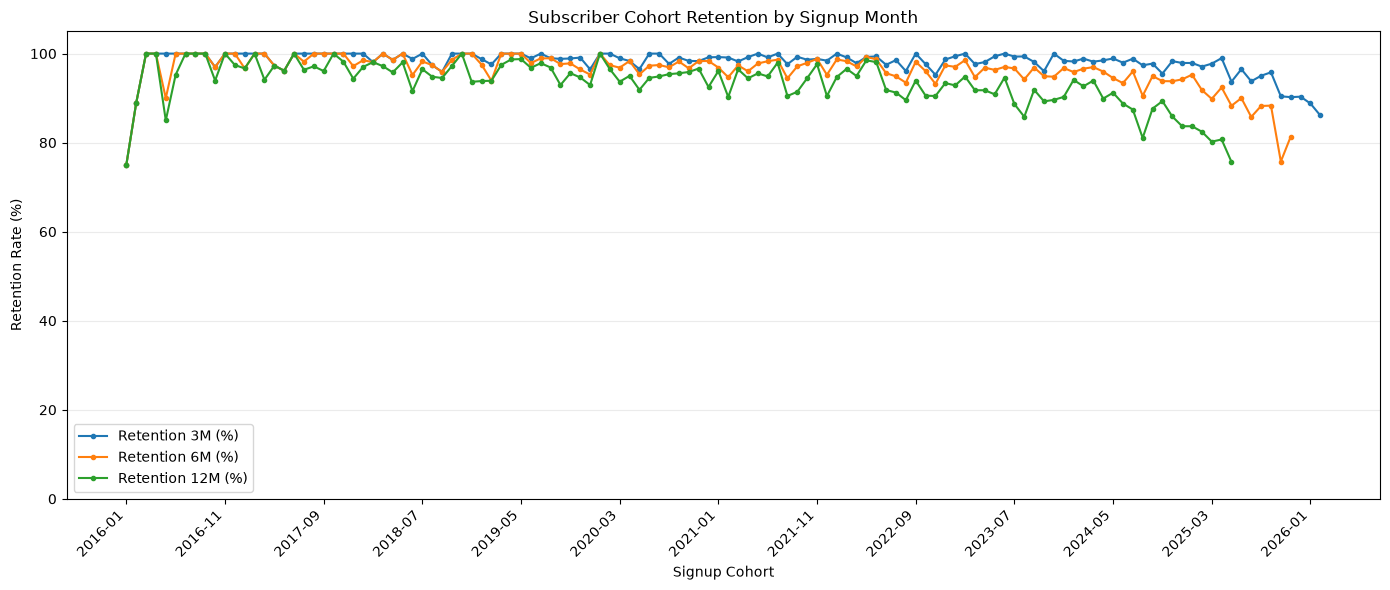

Saved: ..\outputs\charts\phase3\cohort_retention_trend.png


In [29]:
# ------------------------------------------------------------
# COHORT RETENTION TREND
# Plot the retention rates by signup cohort for the three horizons.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

for column in [
    "Retention 3M (%)",
    "Retention 6M (%)",
    "Retention 12M (%)",
]:
    series = cohort_retention_table[column].dropna()

    ax.plot(
        series.index,
        series.values,
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=column,
    )

ax.set_title("Subscriber Cohort Retention by Signup Month")
ax.set_xlabel("Signup Cohort")
ax.set_ylabel("Retention Rate (%)")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.25)

tick_step = max(1, len(cohort_retention_table) // 12)
tick_positions = np.arange(0, len(cohort_retention_table), tick_step)

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    cohort_retention_table.index[tick_positions],
    rotation=45,
    ha="right",
)

fig.tight_layout()

retention_chart_path = CHART_DIR / "cohort_retention_trend.png"
fig.savefig(retention_chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", retention_chart_path)

In [30]:
retention_3m = overall_retention.loc[
    overall_retention["Horizon"] == "3 months",
    "Retention Rate (%)"
].iloc[0]

retention_6m = overall_retention.loc[
    overall_retention["Horizon"] == "6 months",
    "Retention Rate (%)"
].iloc[0]

retention_12m = overall_retention.loc[
    overall_retention["Horizon"] == "12 months",
    "Retention Rate (%)"
].iloc[0]

display(Markdown(
    f"**Bonus finding:** Weighted retention across mature cohorts is "
    f"**{retention_3m:.2f}% at 3 months**, **{retention_6m:.2f}% at 6 months**, "
    f"and **{retention_12m:.2f}% at 12 months**."
))

**Bonus finding:** Weighted retention across mature cohorts is **97.66% at 3 months**, **95.26% at 6 months**, and **92.15% at 12 months**.

## 17. KPI Validation Checks

In [31]:
# ------------------------------------------------------------
# SANITY CHECKS
# These tests verify important mathematical relationships before
# the KPI results are exported.
# ------------------------------------------------------------

validation_checks = pd.DataFrame([
    {
        "check": "Active + inactive = total subscribers",
        "passed": active_subscribers + inactive_subscribers == total_subscribers,
    },
    {
        "check": "Active rate + churn rate = 100%",
        "passed": np.isclose(active_rate + churn_rate, 100.0),
    },
    {
        "check": "MRR is positive",
        "passed": mrr > 0,
    },
    {
        "check": "ARPU formula is correct",
        "passed": np.isclose(arpu, mrr / active_subscribers),
    },
    {
        "check": "Watchlist conversion is within 0-100%",
        "passed": 0 <= watchlist_conversion_rate <= 100,
    },
    {
        "check": "Hit concentration is within 0-100%",
        "passed": 0 <= hit_concentration <= 100,
    },
    {
        "check": "Originals share is within 0-100%",
        "passed": 0 <= originals_share_of_hours <= 100,
    },
])

display(validation_checks)
assert validation_checks["passed"].all()

print("All KPI validation checks passed.")

,check,passed
0,Active + inactive = total subscribers,True
1,Active rate + churn rate = 100%,True
2,MRR is positive,True
3,ARPU formula is correct,True
4,Watchlist conversion is within 0-100%,True
5,Hit concentration is within 0-100%,True
6,Originals share is within 0-100%,True


All KPI validation checks passed.


## 18. Export KPI Outputs

In [32]:
# ------------------------------------------------------------
# EXPORT PHASE 3 OUTPUTS
# These tables can later support Power BI and the management report.
# ------------------------------------------------------------

kpi_summary.to_csv(
    TABLE_DIR / "phase3_kpi_summary.csv",
    index=False
)

target_kpis.to_csv(
    TABLE_DIR / "phase3_target_assessment.csv",
    index=False
)

plays_by_title.reset_index().to_csv(
    TABLE_DIR / "hit_concentration_title_plays.csv",
    index=False
)

cohort_retention_long.to_csv(
    TABLE_DIR / "cohort_retention_long.csv",
    index=False
)

cohort_retention_table.to_csv(
    TABLE_DIR / "cohort_retention_table.csv"
)

overall_retention.to_csv(
    TABLE_DIR / "overall_retention_summary.csv",
    index=False
)

print("Phase 3 output tables exported successfully.")

Phase 3 output tables exported successfully.


## 19. Phase 3 Business Summary

In [33]:
# Generate the written management summary directly from calculated values.
business_summary = f"""
### Phase 3 Business Summary

StreamFlix generated **{total_watch_hours:,.0f} total watch hours** across the available viewing history.

The subscriber base has an **active rate of {active_rate:.2f}%** and a **churn rate of {churn_rate:.2f}%**, so both subscriber-health targets in the project brief are met. Average completion is **{avg_completion_rate:.2f}%**, also above its target.

Current active subscriptions generate approximately **${mrr:,.2f} MRR**, with an **ARPU of ${arpu:,.2f}**. Watchlist conversion is **{watchlist_conversion_rate:.2f}%**, above the 40% target.

The top 10% of titles generate **{hit_concentration:.2f}% of all plays**, while StreamFlix Originals contribute **{originals_share_of_hours:.2f}% of total watch hours**.

The bonus cohort analysis shows weighted retention of approximately **{retention_3m:.2f}% at 3 months**, **{retention_6m:.2f}% at 6 months**, and **{retention_12m:.2f}% at 12 months** across fully mature cohorts.
"""

display(Markdown(business_summary))


### Phase 3 Business Summary

StreamFlix generated **3,333,468 total watch hours** across the available viewing history.

The subscriber base has an **active rate of 74.66%** and a **churn rate of 25.34%**, so both subscriber-health targets in the project brief are met. Average completion is **65.31%**, also above its target.

Current active subscriptions generate approximately **$175,868.51 MRR**, with an **ARPU of $15.70**. Watchlist conversion is **46.23%**, above the 40% target.

The top 10% of titles generate **30.99% of all plays**, while StreamFlix Originals contribute **27.17% of total watch hours**.

The bonus cohort analysis shows weighted retention of approximately **97.66% at 3 months**, **95.26% at 6 months**, and **92.15% at 12 months** across fully mature cohorts.


## 20. PRD Requirement Checklist

In [34]:
prd_checklist = pd.DataFrame([
    ["Total Watch Hours", "Complete"],
    ["Active Rate", "Complete"],
    ["Churn Rate", "Complete"],
    ["Average Completion Rate", "Complete"],
    ["Monthly Recurring Revenue", "Complete"],
    ["ARPU", "Complete"],
    ["Average Watch Time / Subscriber", "Complete"],
    ["Watchlist Conversion", "Complete"],
    ["Hit Concentration", "Complete"],
    ["Originals Share of Hours", "Complete"],
    ["Bonus Cohort Retention — 3 months", "Complete"],
    ["Bonus Cohort Retention — 6 months", "Complete"],
    ["Bonus Cohort Retention — 12 months", "Complete"],
], columns=["Requirement", "Status"])

display(prd_checklist)

prd_checklist.to_csv(
    TABLE_DIR / "prd_requirement_checklist.csv",
    index=False
)

,Requirement,Status
0,Total Watch Hours,Complete
1,Active Rate,Complete
2,Churn Rate,Complete
3,Average Completion Rate,Complete
4,Monthly Recurring Revenue,Complete
5,ARPU,Complete
6,Average Watch Time / Subscriber,Complete
7,Watchlist Conversion,Complete
8,Hit Concentration,Complete
9,Originals Share of Hours,Complete


## 21. Phase 3 Conclusion

Phase 3 successfully calculates all **10 required business KPIs** and completes the optional cohort-retention challenge.

The results show that StreamFlix currently meets all four explicit thresholds stated in the brief: **Active Rate, Churn Rate, Average Completion Rate, and Watchlist Conversion**. The revenue, engagement, concentration, and Originals metrics now provide the quantitative foundation for the Phase 4 Power BI dashboard and management report.

## 22. Phase 3 Completion Status

In [35]:
print("=" * 72)
print("STREAMFLIX PHASE 3 — KPI CALCULATIONS")
print("=" * 72)
print("Status            : COMPLETE")
print("Required KPIs     : 10 / 10")
print("Explicit targets  : 4 / 4 assessed")
print("Bonus retention   : COMPLETE")
print("Validation checks : PASSED")
print("Next phase        : Phase 4 — Dashboard & Final Report")
print("=" * 72)

STREAMFLIX PHASE 3 — KPI CALCULATIONS
Status            : COMPLETE
Required KPIs     : 10 / 10
Explicit targets  : 4 / 4 assessed
Bonus retention   : COMPLETE
Validation checks : PASSED
Next phase        : Phase 4 — Dashboard & Final Report
